# Forecast 3 — Machine Learning for Streamflow Prediction

*CEE 306: Hydrology — Water and Climate | Spring 2026*

**Forecast Team Name:** `<HBO>`

**Names:** `<Sayfullo Saidov, Muhammad Omer, Wunnyuriti Ziblim>`

**Forecasted Dates:** `Friday April 24th - Sunday April 26th`

This notebook documents a course forecasting exercise using a convolutional neural network (CNN). Course-provided machine-learning helper scripts are required to run the original code; the model architecture is credited to Professor Reed Maxwell. Original code cells and saved outputs are retained.

## Python imports

In [1]:
import pandas as pd
import numpy as np
import json, requests
import matplotlib.pyplot as plt
import datetime

## Historical observations and weather forecast

In [2]:
## get the forecast for temperature and precipitation
headers = {
'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/71.0.3578.98 Safari/537.36',
'Accept' : 'text/html,application/xhtml+xml,application/xml;q=0.9,*/*;q=0.8',
'Accept-Language' : 'en-US,en;q=0.5',
'Accept-Encoding' : 'gzip',
'DNT' : '1', # Do Not Track Request Header
'Connection' : 'close' }
url = requests.get("https://api.weather.gov/gridpoints/PHI/63,95/", headers=headers)

data_json = json.loads(url.text)

data = pd.DataFrame(columns=('DateTime','Precip [mm]','Temp [C]'))
for i in range(12):
    data.loc[i] = [data_json['properties']['quantitativePrecipitation']['values'][i]['validTime'],
                   data_json['properties']['quantitativePrecipitation']['values'][i]['value'],
                   data_json['properties']['temperature']['values'][i]['value']]

# note the cumulative sum calculations and conversions below
data['DateTime'] = data['DateTime'].str.slice(stop=16)
data['cum_precip_mm'] = data['Precip [mm]'].cumsum()
data['Precip_ft'] = data['Precip [mm]']*0.00328084
data['Precip_in'] = data['Precip [mm]']*0.0393701
data['cum_precip_in'] = data['Precip_in'].cumsum()
print(data)

            DateTime Precip [mm]   Temp [C] cum_precip_mm Precip_ft Precip_in  \
0   2026-04-24T02:00           0  17.777778             0       0.0       0.0   
1   2026-04-24T06:00           0  16.666667             0       0.0       0.0   
2   2026-04-24T12:00           0  14.444444             0       0.0       0.0   
3   2026-04-24T18:00           0  12.777778             0       0.0       0.0   
4   2026-04-25T00:00           0  11.666667             0       0.0       0.0   
5   2026-04-25T06:00       0.508  11.111111         0.508  0.001667      0.02   
6   2026-04-25T12:00       9.398  10.000000         9.906  0.030833      0.37   
7   2026-04-25T18:00      10.922   9.444444        20.828  0.035833      0.43   
8   2026-04-26T00:00        6.35   8.888889        27.178  0.020833      0.25   
9   2026-04-26T06:00       6.096  10.000000        33.274      0.02      0.24   
10  2026-04-26T12:00       2.286  11.666667         35.56    0.0075      0.09   
11  2026-04-26T18:00       1

In [3]:
## now let's get past week of streamflow and precipitation - using the same url process as before
period = "P7D"
# agian, feel free to print and look at those URLs

# streamflow from Stony Brook
flow_url = "https://nwis.waterdata.usgs.gov/nwis/iv/?format=rdb&sites=01401000&period="+period+"&parameterCd=00060&siteStatus=all"
StonyBrook = pd.read_csv(flow_url, skiprows=28, sep='\t', header=None)
StonyBrook.columns = ["agency_cd","site_no","datetime_stony","tz_cd","flow_cfs","194689_00060_cd"]

# precip from Skillman
precip_url = "https://nwis.waterdata.usgs.gov/nwis/iv/?format=rdb&sites=402504074414201&period="+period+"&parameterCd=00045&siteStatus=all"
Skillman = pd.read_csv(precip_url, skiprows=28, sep='\t', header=None)
Skillman.columns = ["agency_cd","site_no","datetime_skill","tz_cd","precip_in","Cumulative_Precip"]
Skillman['cum_precip_in'] = Skillman['precip_in'].cumsum()

# air temperature from Trenton
airtemp_url = "https://waterdata.usgs.gov/nwis/uv?cb_00021=on&format=rdb&site_no=401121074452101&period="+period
Trenton = pd.read_csv(airtemp_url, skiprows=28, sep='\t', header=None)
Trenton.columns = ['agency_cd','site_no',"datetime_trent","tz",'airTemp_F','description']

## if you want, uncomment the below code to see the csv url links, and a sample of the dataframes
print(f'Streamflow csv URL: {flow_url}')
print(StonyBrook.head(5),'\n')
print(f'Precipitation csv URL: {precip_url}')
print(Skillman.head(5),'\n')
print(f'Air temperature URL: {airtemp_url}')
print(Trenton.head(5),'\n')

Streamflow csv URL: https://nwis.waterdata.usgs.gov/nwis/iv/?format=rdb&sites=01401000&period=P7D&parameterCd=00060&siteStatus=all
  agency_cd  site_no    datetime_stony tz_cd  flow_cfs 194689_00060_cd
0      USGS  1401000  2026-04-17 06:30   EDT      14.1               P
1      USGS  1401000  2026-04-17 06:45   EDT      14.1               P
2      USGS  1401000  2026-04-17 07:00   EDT      14.1               P
3      USGS  1401000  2026-04-17 07:15   EDT      14.1               P
4      USGS  1401000  2026-04-17 07:30   EDT      14.1               P 

Precipitation csv URL: https://nwis.waterdata.usgs.gov/nwis/iv/?format=rdb&sites=402504074414201&period=P7D&parameterCd=00045&siteStatus=all
  agency_cd          site_no    datetime_skill tz_cd  precip_in  \
0      USGS  402504074414201  2026-04-17 06:30   EDT        0.0   
1      USGS  402504074414201  2026-04-17 06:45   EDT        0.0   
2      USGS  402504074414201  2026-04-17 07:00   EDT        0.0   
3      USGS  402504074414201  20

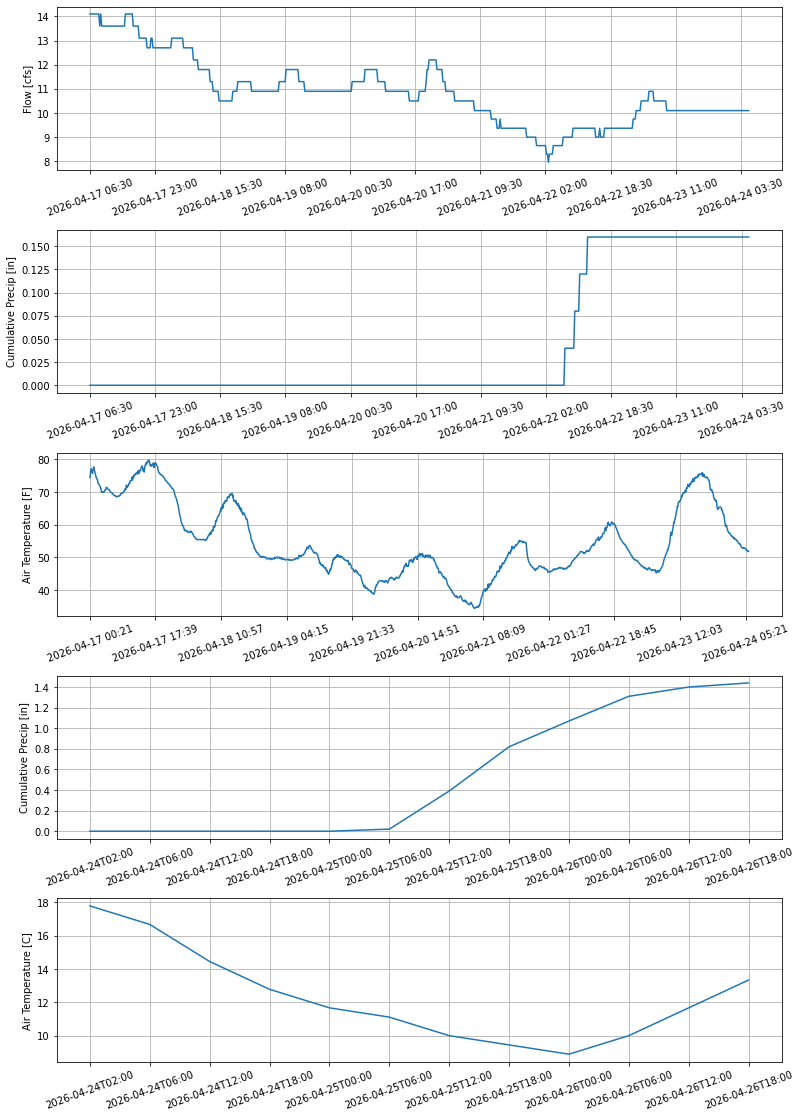

In [4]:
## plot data
## set up figure with 4 plots
fig, axs = plt.subplots(5,figsize=(12,16))

## plot past streamflow
axs[0].plot(StonyBrook['datetime_stony'],StonyBrook['flow_cfs'])
axs[0].set_xticks(StonyBrook['datetime_stony'][::len(StonyBrook['datetime_stony']) // 10])
axs[0].set_ylabel('Flow [cfs]')

## plot past precipitation
axs[1].plot(Skillman['datetime_skill'],Skillman['cum_precip_in'])
axs[1].set_xticks(Skillman['datetime_skill'][::len(Skillman['datetime_skill']) // 10])
axs[1].set_ylabel('Cumulative Precip [in]')

## plot past air temperature
axs[2].plot(Trenton['datetime_trent'],Trenton['airTemp_F'])
axs[2].set_xticks(Trenton['datetime_trent'][::len(Trenton['datetime_trent']) // 10])
axs[2].set_ylabel('Air Temperature [F]')

## plot forecast precip
axs[3].plot(data['DateTime'],data['cum_precip_in'])
axs[3].set_ylabel('Cumulative Precip [in]')

## plot forecast air temp
axs[4].plot(data['DateTime'],data['Temp [C]'])
axs[4].set_ylabel('Air Temperature [C]')

# put space between plots
fig.tight_layout(pad=4.0)

# add a grid and rotate the x-axis labels on each plot
for i in range(5):
    axs[i].grid()
    axs[i].tick_params(axis='x', labelrotation = 20)

## CNN streamflow forecasting

### Forecast model implementation

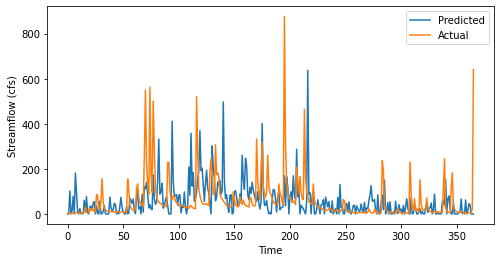

RMSE: 111.4981888456771
NSE: -0.30913067068053746
KGE: 0.1675032615209966


In [5]:
# importing whatever is needed
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from rmm_nn import RMM_NN
from transform import float32_clamp_scaling
from permetrics.regression import RegressionMetric

DEVICE = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')



# CNN FUNCTION FOR STREAMFLOW (just reusing and adjusting the given code)

def cnn_flow(n_batch, N, n_epoch, n_batch_test, learning_rate, train_data, test_data):

    nchannel = 2  # temp + precip

    model = RMM_NN(grid_size=[N], channels=nchannel)
    model.to(DEVICE)
    model.verbose = False
    model.use_dropout = True

    loss_fn = torch.nn.SmoothL1Loss()
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

    # Normalization
    flow_max = np.max(train_data['flow'])
    precip_max = np.max(train_data['precip'])

    Temp_TRANSF = float32_clamp_scaling(
        src_range=[np.min(train_data['temp']), np.max(train_data['temp'])],
        dst_range=[-1, 1]
    )
    Flow_TRANSF = float32_clamp_scaling(src_range=[0, flow_max], dst_range=[0, 1])
    Precip_TRANSF = float32_clamp_scaling(src_range=[0, precip_max], dst_range=[0, 1])

    INV_FLOW_TRANSF = float32_clamp_scaling(src_range=[0, 1], dst_range=[0, flow_max])

    # Preparing training arrays
    input_temp = np.zeros((n_batch, nchannel, N))
    output_temp = np.zeros((n_batch, N))

    P_temp = Precip_TRANSF(np.asarray(train_data['precip']))
    T_temp = Temp_TRANSF(np.asarray(train_data['temp']))
    flow_temp = Flow_TRANSF(np.asarray(train_data['flow']))

    for ii in range(n_batch):
        i_from = ii * N
        i_to = i_from + N
        input_temp[ii, 0, :] = P_temp[i_from:i_to]
        input_temp[ii, 1, :] = T_temp[i_from:i_to]
        output_temp[ii, :] = flow_temp[i_from:i_to]

    torch_input = torch.from_numpy(input_temp).type(torch.FloatTensor).to(DEVICE)
    torch_label = torch.from_numpy(output_temp).type(torch.FloatTensor).to(DEVICE)

    # Training loop
    for epoch in range(n_epoch):
        optimizer.zero_grad()
        prediction = model(torch_input)
        loss = loss_fn(prediction, torch_label)
        loss.backward()
        optimizer.step()

    # Freezing model
    model.use_dropout = False
    for p in model.parameters():
        p.requires_grad = False

    # Preparing test input
    P_temp = Precip_TRANSF(np.asarray(test_data['precip']))
    T_temp = Temp_TRANSF(np.asarray(test_data['temp']))

    input_test = np.zeros((n_batch_test, nchannel, N))

    for ii in range(n_batch_test):
        i_from = ii * N
        i_to = i_from + N
        input_test[ii, 0, :] = P_temp[i_from:i_to]
        input_test[ii, 1, :] = T_temp[i_from:i_to]

    predict_input = torch.from_numpy(input_test).type(torch.FloatTensor).to(DEVICE)

    prediction = model(predict_input)
    model_output = INV_FLOW_TRANSF(prediction.data.cpu().numpy())

    model_plot = np.reshape(model_output, (N * n_batch_test))

    return model_plot



# LOADING DATA & CORRESPONDING DATES
# We have not altered any test data/ train data period as this is just extracting the code from HW4. We tried changing it in the forecast code. 

train_start_date = '2014-10-01'
train_end_date   = '2019-09-30'
wtrain_end_date  = '2019-10-01'

test_start_date  = '2019-10-01'
test_end_date    = '2020-09-30'


#  Weather for Training

url = f"https://daymet.ornl.gov/single-pixel/send/saveData?lat=40.3573&lon=-74.6672&start={train_start_date}&end={wtrain_end_date}&format=csv"
weather = pd.read_csv(url, skiprows=6)

weather['temp'] = (weather['tmax (deg c)'] + weather['tmin (deg c)']) / 2
weather['precip'] = weather['prcp (mm/day)']

# Streamflow for Training

url = f"https://nwis.waterdata.usgs.gov/nj/nwis/uv/?cb_00060=on&format=rdb&site_no=01401000&begin_date={train_start_date}&end_date={train_end_date}"
flow = pd.read_csv(url, sep='\t', skiprows=25)

flow.columns = ['agency','site','datetime','tz','flow','id']
flow['datetime'] = pd.to_datetime(flow['datetime'])
flow_daily = flow.set_index('datetime')['flow'].resample('D').mean().reset_index()

train_data = pd.DataFrame({
    'temp': weather['temp'].values,
    'precip': weather['precip'].values,
    'flow': flow_daily['flow'].values
}).dropna().reset_index(drop=True)


# Weather for Testing

url = f"https://daymet.ornl.gov/single-pixel/send/saveData?lat=40.3573&lon=-74.6672&start={test_start_date}&end={test_end_date}&format=csv"
weather = pd.read_csv(url, skiprows=6)

weather['temp'] = (weather['tmax (deg c)'] + weather['tmin (deg c)']) / 2
weather['precip'] = weather['prcp (mm/day)']

# Streamflow for Testing 
url = f"https://nwis.waterdata.usgs.gov/nj/nwis/uv/?cb_00060=on&format=rdb&site_no=01401000&begin_date={test_start_date}&end_date={test_end_date}"
flow = pd.read_csv(url, sep='\t', skiprows=25)

flow.columns = ['agency','site','datetime','tz','flow','id']
flow['datetime'] = pd.to_datetime(flow['datetime'])
flow_daily = flow.set_index('datetime')['flow'].resample('D').mean().reset_index()

test_data = pd.DataFrame({
    'temp': weather['temp'].values,
    'precip': weather['precip'].values,
    'flow': flow_daily['flow'].values
}).dropna().reset_index(drop=True)


# RUN THE MODEL
N = 366  # In HW4, we tried 3 and 366

n_batch = int(len(train_data) / N)
n_batch_test = int(len(test_data) / N)

n_epoch = 100
learning_rate = 1e-3

model_output = cnn_flow(
    n_batch, N, n_epoch,
    n_batch_test, learning_rate,
    train_data, test_data
)



# PLOT & RESULTS

plt.figure(figsize=(8,4))
plt.plot(model_output, label='Predicted')
plt.plot(test_data['flow'], label='Actual')
plt.xlabel('Time')
plt.ylabel('Streamflow (cfs)')
plt.legend()
plt.show()



# VALIDATION CHECKS
y_true = np.array(test_data['flow'])
y_pred = model_output

evaluator = RegressionMetric(y_true, y_pred)

print("RMSE:", evaluator.root_mean_squared_error())
print("NSE:", evaluator.nash_sutcliffe_efficiency())
print("KGE:", evaluator.kling_gupta_efficiency())

Using device: cpu
Loading training data (2010-2023)...
  Loaded 4677 days  (2010-10-01 to 2023-09-30)
Loading validation data (2023-2024)...
  Loaded 366 days  (2023-10-01 to 2024-09-30)
Fetching recent observed flow (last 90 days)...
  Fetched 91 days of recent observed flow

--- Scaler ranges ---
  Temp        : -13.2 to 32.5 C
  Precip      : 0 to 176.1 mm
  Flow (log)  : 0.69 to 8.63
  Flow (raw)  : 1.0 to 5617.9 cfs
---------------------

Training: 77 batches x 60 days x 1000 epochs  |  3 channels (precip, temp, past flow)
  Epoch  100/1000  Loss: 0.009923
  Epoch  200/1000  Loss: 0.005197
  Epoch  300/1000  Loss: 0.004157
  Epoch  400/1000  Loss: 0.003468
  Epoch  500/1000  Loss: 0.003100
  Epoch  600/1000  Loss: 0.003131
  Epoch  700/1000  Loss: 0.003033
  Epoch  800/1000  Loss: 0.003027
  Epoch  900/1000  Loss: 0.002713
  Epoch 1000/1000  Loss: 0.002825
Training complete.

=== Validation on 2023-2024 ===
  RMSE : 218.98 cfs
  NSE  : 0.3295  (>0.6 = good)
  KGE  : 0.3309  (>0.6 

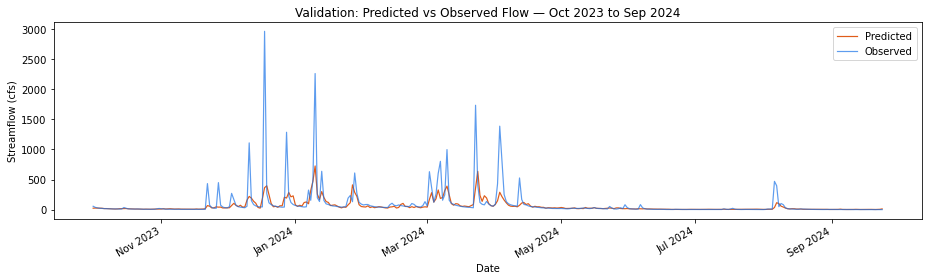

Fetching live NWS forecast for Apr 24-26...
      date  precip      temp
2026-04-24   0.000 15.079365
2026-04-25  20.828  9.824561
2026-04-26  15.748  8.134921

Running sliding-window forecast...
  2026-04-24  temp=15.1C  precip=0.00mm  past_flow=10.1cfs  -> predicted flow = 11.8 cfs
  2026-04-25  temp=9.8C  precip=20.83mm  past_flow=11.8cfs  -> predicted flow = 15.9 cfs
  2026-04-26  temp=8.1C  precip=15.75mm  past_flow=15.9cfs  -> predicted flow = 22.5 cfs


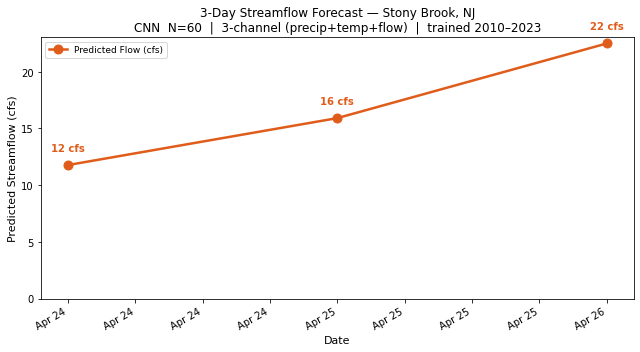


=== 3-Day Streamflow Forecast ===
Date            Precip (mm)     Temp (C)      Predicted Flow (cfs)
------------------------------------------------------------
2026-04-24      0.00            15.1          11.8
2026-04-25      20.83           9.8           15.9
2026-04-26      15.75           8.1           22.5


In [15]:
#importing crucial Python methods 

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import torch
import requests

from rmm_nn import RMM_NN
from transform import float32_clamp_scaling
from permetrics.regression import RegressionMetric

# Here it is deciding whether it can use CPU or GPU if available (important for speed)


DEVICE = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {DEVICE}")

# LOADING DATA (Weather + Streamflow merged by date)
#As we often faced the issue of array length mismatch, we decided to merge the data, so it considers only matching dates

def load_data(start_date, end_date):
    url = (
        f"https://daymet.ornl.gov/single-pixel/send/saveData"
        f"?lat=40.3573&lon=-74.6672"
        f"&start={start_date}&end={end_date}&format=csv"
    )
    weather = pd.read_csv(url, skiprows=6)
    weather['date'] = pd.to_datetime(
        weather['year'].astype(str) + '-' +
        weather['yday'].astype(str).str.zfill(3), format='%Y-%j'
    )
    weather['temp']   = (weather['tmax (deg c)'] + weather['tmin (deg c)']) / 2
    weather['precip'] = weather['prcp (mm/day)']
    weather = weather[['date', 'temp', 'precip']]

    url = (
        f"https://nwis.waterdata.usgs.gov/nj/nwis/uv/"
        f"?cb_00060=on&format=rdb&site_no=01401000"
        f"&begin_date={start_date}&end_date={end_date}"
    )
    flow_raw = pd.read_csv(url, sep='\t', skiprows=25)
    flow_raw.columns = ['agency', 'site', 'datetime', 'tz', 'flow', 'id']
    flow_raw['datetime'] = pd.to_datetime(flow_raw['datetime'], errors='coerce')
    flow_raw = flow_raw.dropna(subset=['datetime'])
    flow_raw['flow'] = pd.to_numeric(flow_raw['flow'], errors='coerce')

        # Converting to daily mean flow (important for consistency with weather data)

    
    flow_daily = (
        flow_raw.set_index('datetime')['flow']
        .resample('D').mean().reset_index()
        .rename(columns={'datetime': 'date'})
    )
    flow_daily['date'] = flow_daily['date'].dt.normalize()

        # Align weather + flow perfectly by date

    data = pd.merge(weather, flow_daily, on='date', how='inner').dropna().reset_index(drop=True)
    data['flow'] = data['flow'].clip(lower=1.0)
    print(f"  Loaded {len(data)} days  ({start_date} to {end_date})")
    return data

#We are adding third channel - past flow

def fetch_recent_observed_flow(n_days=90):
    """Fetch the most recent n_days of observed daily flow from Stony Brook."""
    url = (
        f"https://nwis.waterdata.usgs.gov/nwis/iv/?format=rdb&sites=01401000"
        f"&period=P{n_days}D&parameterCd=00060&siteStatus=all"
    )
    raw = pd.read_csv(url, sep='\t', skiprows=28, header=None)
    raw.columns = ['agency_cd', 'site_no', 'datetime_stony', 'tz_cd', 'flow_cfs', 'flag']
    raw['datetime_stony'] = pd.to_datetime(raw['datetime_stony'], errors='coerce')
    raw = raw.dropna(subset=['datetime_stony'])
    raw['flow_cfs'] = pd.to_numeric(raw['flow_cfs'], errors='coerce')
    daily = (
        raw.set_index('datetime_stony')['flow_cfs']
        .resample('D').mean().reset_index()
        .rename(columns={'datetime_stony': 'date', 'flow_cfs': 'flow'})
    )
    daily['flow'] = daily['flow'].clip(lower=1.0)
    print(f"  Fetched {len(daily)} days of recent observed flow")
    return daily

# TRAINING (Separated Training function for clarity)


def train_cnn_flow(n_batch, N, n_epoch, learning_rate, train_data):
    nchannel = 3  # precip, temp, past flow. So, we added the third channel

        # Initializing CNN model

    model = RMM_NN(grid_size=[N], channels=nchannel)
    model.to(DEVICE)
    model.verbose     = False
    model.use_dropout = True

    loss_fn   = torch.nn.SmoothL1Loss()
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    
        # Here, we are normalizing inputs - very important step as discussed for NN stability 


    precip_max = np.max(train_data['precip'])
    temp_min   = np.min(train_data['temp'])
    temp_max   = np.max(train_data['temp'])
    log_flow   = np.log1p(train_data['flow'])
    lf_min, lf_max = np.min(log_flow), np.max(log_flow)

    print(f"\n--- Scaler ranges ---")
    print(f"  Temp        : {temp_min:.1f} to {temp_max:.1f} C")
    print(f"  Precip      : 0 to {precip_max:.1f} mm")
    print(f"  Flow (log)  : {lf_min:.2f} to {lf_max:.2f}")
    print(f"  Flow (raw)  : {np.min(train_data['flow']):.1f} to {np.max(train_data['flow']):.1f} cfs")
    print(f"---------------------\n")

    Temp_TRANSF        = float32_clamp_scaling(src_range=[temp_min, temp_max], dst_range=[-1, 1])
    Precip_TRANSF      = float32_clamp_scaling(src_range=[0, precip_max],      dst_range=[0, 1])
    LogFlow_TRANSF     = float32_clamp_scaling(src_range=[lf_min, lf_max],     dst_range=[0, 1])
    INV_LogFlow_TRANSF = float32_clamp_scaling(src_range=[0, 1],               dst_range=[lf_min, lf_max])

        #Creating training batches (fixed-length time windows)

    
    P_scaled    = Precip_TRANSF(np.asarray(train_data['precip']))
    T_scaled    = Temp_TRANSF(np.asarray(train_data['temp']))
    Flow_scaled = LogFlow_TRANSF(np.asarray(log_flow))
    
    # CNN input is [precip, temp, past flow] over time window

    input_arr  = np.zeros((n_batch, nchannel, N))
    output_arr = np.zeros((n_batch, N))
    for ii in range(n_batch):
        i_from = ii * N
        i_to   = i_from + N
        input_arr[ii, 0, :] = P_scaled[i_from:i_to]
        input_arr[ii, 1, :] = T_scaled[i_from:i_to]
        
        
        # channel. third: past flow: shifting by 1 so input[t] = flow[t-1] (input is the last day's flow)
        # for the first day of each batch, it uses the last known value before window
        
        if i_from > 0:
            past_flow = np.concatenate([[Flow_scaled[i_from - 1]], Flow_scaled[i_from:i_to - 1]])
        else:
            past_flow = np.concatenate([[Flow_scaled[0]], Flow_scaled[i_from:i_to - 1]])
        input_arr[ii, 2, :] = past_flow
        
                # Model Target is flow over same time window

        output_arr[ii, :]   = Flow_scaled[i_from:i_to]

    torch_input = torch.from_numpy(input_arr).float().to(DEVICE)
    torch_label = torch.from_numpy(output_arr).float().to(DEVICE)
    
    #As there are many print steps, we can see where the model is failing if we have an error. Thus, printing every step helps us.
    
    # Training loop

    print(f"Training: {n_batch} batches x {N} days x {n_epoch} epochs  |  3 channels (precip, temp, past flow)")
    for epoch in range(n_epoch):
        optimizer.zero_grad()
        prediction = model(torch_input)
        loss = loss_fn(prediction, torch_label)
        loss.backward()
        optimizer.step()
        if (epoch + 1) % 100 == 0:
            print(f"  Epoch {epoch+1:4d}/{n_epoch}  Loss: {loss.item():.6f}")

    model.use_dropout = False
    for p in model.parameters():
        p.requires_grad = False

    print("Training complete.\n")
    return model, Temp_TRANSF, Precip_TRANSF, LogFlow_TRANSF, INV_LogFlow_TRANSF


def inv_log_transform(scaled_arr, INV_LogFlow_TRANSF):
    return np.expm1(INV_LogFlow_TRANSF(scaled_arr))


# PREDICTING — for validation

def predict_flow(model, Temp_TRANSF, Precip_TRANSF, LogFlow_TRANSF,
                 INV_LogFlow_TRANSF, input_data, N):
    n_batches = int(len(input_data) / N)
    if n_batches == 0:
        raise ValueError(f"Input has {len(input_data)} rows but model needs multiples of N={N}.")

    P_scaled    = Precip_TRANSF(np.asarray(input_data['precip']))
    T_scaled    = Temp_TRANSF(np.asarray(input_data['temp']))
    Flow_scaled = LogFlow_TRANSF(np.log1p(np.asarray(input_data['flow'])))

    input_arr = np.zeros((n_batches, 3, N))
    for ii in range(n_batches):
        i_from = ii * N
        i_to   = i_from + N
        input_arr[ii, 0, :] = P_scaled[i_from:i_to]
        input_arr[ii, 1, :] = T_scaled[i_from:i_to]
        if i_from > 0:
            past = np.concatenate([[Flow_scaled[i_from - 1]], Flow_scaled[i_from:i_to - 1]])
        else:
            past = np.concatenate([[Flow_scaled[0]], Flow_scaled[i_from:i_to - 1]])
        input_arr[ii, 2, :] = past

    tensor_in = torch.from_numpy(input_arr).float().to(DEVICE)
    with torch.no_grad():
        raw_pred = model(tensor_in)

    flat = np.reshape(raw_pred.cpu().numpy(), (N * n_batches,))
    return inv_log_transform(flat, INV_LogFlow_TRANSF)


# FORECAST function

def forecast_next_days(model, Temp_TRANSF, Precip_TRANSF, LogFlow_TRANSF,
                       INV_LogFlow_TRANSF, forecast_df, train_data,
                       recent_obs_flow, N):
   
    #Rolling forecast
    #Past flow channel uses real observed flow for as long as we have it,
    #then switches to the model's own predictions.
    
     # Startinh with the last N days of observed history as a rolling buffer
    # Sliding this forward one day at a time
    # We thought this is more accurate way of doing it as it seems our CNN model is relatively short-term memory one.
    
    #Shortly forecast cnn function is applying a trained model in a rolling (recursive) way to simulate future flow
    
    history_temp   = list(train_data['temp'].values[-N:])
    history_precip = list(train_data['precip'].values[-N:])

    # Build flow history: it prefers recent observed, falls back to training tail
    obs_flow_vals = list(recent_obs_flow['flow'].values)
    if len(obs_flow_vals) >= N:
        history_flow = obs_flow_vals[-N:]
    else:
        n_needed = N - len(obs_flow_vals)
        history_flow = list(train_data['flow'].values[-n_needed:]) + obs_flow_vals

    predicted_flows = []

    for i in range(len(forecast_df)):
        fc_temp   = forecast_df['temp'].iloc[i]
        fc_precip = forecast_df['precip'].iloc[i]

        # For past flow channel, it uses yesterday's value (last in history)
        fc_past_flow = history_flow[-1]

        window_temp    = history_temp[1:]   + [fc_temp]
        window_precip  = history_precip[1:] + [fc_precip]
        window_flow    = history_flow[1:]   + [fc_past_flow]  # will be overwritten next step

        t_scaled  = Temp_TRANSF(np.array(window_temp,   dtype=np.float32))
        p_scaled  = Precip_TRANSF(np.array(window_precip, dtype=np.float32))
        lf_scaled = LogFlow_TRANSF(np.log1p(np.array(window_flow, dtype=np.float32)))

        input_arr = np.zeros((1, 3, N), dtype=np.float32)
        input_arr[0, 0, :] = p_scaled
        input_arr[0, 1, :] = t_scaled
        input_arr[0, 2, :] = lf_scaled

        tensor_in = torch.from_numpy(input_arr).to(DEVICE)
        with torch.no_grad():
            raw_pred = model(tensor_in)

        pred_scaled = raw_pred.cpu().numpy()[0, -1]
        pred_flow   = inv_log_transform(np.array([pred_scaled]), INV_LogFlow_TRANSF)[0]
        predicted_flows.append(float(pred_flow))

        # Advance buffers — use predicted flow as next step's past flow
        history_temp   = window_temp
        history_precip = window_precip
        history_flow   = history_flow[1:] + [pred_flow]

        print(f"  {str(forecast_df['date'].iloc[i].date())}  "
              f"temp={fc_temp:.1f}C  precip={fc_precip:.2f}mm  "
              f"past_flow={fc_past_flow:.1f}cfs  "
              f"-> predicted flow = {pred_flow:.1f} cfs")

    return np.array(predicted_flows)


# For weather information of forecast, we are using NWS API. So fetching it. 


def fetch_nws_forecast_daily(target_dates):
    headers = {'User-Agent': 'Mozilla/5.0', 'Accept': 'application/json'}
    resp = requests.get(
        "https://api.weather.gov/gridpoints/PHI/63,95/",
        headers=headers, timeout=30
    )
    resp.raise_for_status()
    props = resp.json()['properties']

    precip_rows = []
    for rec in props['quantitativePrecipitation']['values']:
        dt = pd.to_datetime(rec['validTime'].split('/')[0], utc=True).tz_localize(None)
        precip_rows.append({'date': dt.normalize(), 'precip': rec['value']})
    precip_daily = pd.DataFrame(precip_rows).groupby('date')['precip'].sum().reset_index()

    temp_rows = []
    for rec in props['temperature']['values']:
        dt = pd.to_datetime(rec['validTime'].split('/')[0], utc=True).tz_localize(None)
        temp_rows.append({'date': dt.normalize(), 'temp': rec['value']})
    temp_df = pd.DataFrame(temp_rows)
    if temp_df['temp'].mean() > 200:
        temp_df['temp'] -= 273.15
    temp_daily = temp_df.groupby('date')['temp'].mean().reset_index()

    forecast = pd.merge(precip_daily, temp_daily, on='date')
    target_norm = [pd.Timestamp(d).normalize() for d in target_dates]
    rows = []
    for td in target_norm:
        match = forecast[forecast['date'] == td]
        if len(match) > 0:
            rows.append(match.iloc[0].to_dict())
        else:
            nearest = forecast.iloc[(forecast['date'] - td).abs().argsort()].iloc[0]
            rows.append({'date': td, 'precip': 0.0, 'temp': float(nearest['temp'])})

    result = pd.DataFrame(rows).reset_index(drop=True)
    result['date'] = pd.to_datetime(result['date'])
    return result


# LOADING DATA

print("=" * 55)
print("Loading training data (2010-2023)...")
train_data = load_data('2010-10-01', '2023-09-30')

print("Loading validation data (2023-2024)...")
test_data  = load_data('2023-10-01', '2024-09-30')

print("Fetching recent observed flow (last 90 days)...")
recent_obs_flow = fetch_recent_observed_flow(n_days=90)


# PARAMETERS: we are tuning these

N             = 60
n_epoch       = 1000
learning_rate = 0.001


# TRAIN

n_batch = int(len(train_data) / N)

model, Temp_TRANSF, Precip_TRANSF, LogFlow_TRANSF, INV_LogFlow_TRANSF = train_cnn_flow(
    n_batch, N, n_epoch, learning_rate, train_data
)


# VALIDATING ON 2023-2024

val_pred = predict_flow(model, Temp_TRANSF, Precip_TRANSF, LogFlow_TRANSF,
                        INV_LogFlow_TRANSF, test_data, N)

y_true    = np.array(test_data['flow'][:len(val_pred)])
evaluator = RegressionMetric(y_true, val_pred)
print("=== Validation on 2023-2024 ===")
print(f"  RMSE : {evaluator.root_mean_squared_error():.2f} cfs")
print(f"  NSE  : {evaluator.nash_sutcliffe_efficiency():.4f}  (>0.6 = good)")
print(f"  KGE  : {evaluator.kling_gupta_efficiency():.4f}  (>0.6 = good)\n")

# Validation plot


test_dates = test_data['date'].values[:len(val_pred)]
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(test_dates, val_pred,
        label='Predicted', color='#E05C1A', linewidth=1.2)
ax.plot(test_dates, test_data['flow'].values[:len(val_pred)],
        label='Observed',  color='#1A73E8', linewidth=1.2, alpha=0.7)
ax.set_title('Validation: Predicted vs Observed Flow — Oct 2023 to Sep 2024')
ax.set_xlabel('Date')
ax.set_ylabel('Streamflow (cfs)')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
fig.autofmt_xdate()
ax.legend()
plt.tight_layout()
plt.show()


# FORECAST of the next 3 days. Now actually running all the functions written above to find the result


target_dates = [
    pd.Timestamp('2026-04-24'),
    pd.Timestamp('2026-04-25'),
    pd.Timestamp('2026-04-26'),
]

print("=" * 55)
print("Fetching live NWS forecast for Apr 24-26...")
forecast_df = fetch_nws_forecast_daily(target_dates)
print(forecast_df.to_string(index=False))
print()

print("Running sliding-window forecast...")
forecast_flow = forecast_next_days(
    model, Temp_TRANSF, Precip_TRANSF, LogFlow_TRANSF, INV_LogFlow_TRANSF,
    forecast_df, train_data, recent_obs_flow, N
)


# FORECAST PLOT 

dates = forecast_df['date'].values
fig, ax = plt.subplots(figsize=(9, 5))
flow_color = '#E05C1A'
ax.plot(dates, forecast_flow, color=flow_color, linewidth=2.5,
        marker='o', markersize=9, label='Predicted Flow (cfs)', zorder=5)
for d, f in zip(dates, forecast_flow):
    ax.annotate(f'{f:.0f} cfs', xy=(d, f), xytext=(0, 14),
                textcoords='offset points', ha='center',
                fontsize=10, color=flow_color, fontweight='bold')
ax.set_ylabel('Predicted Streamflow (cfs)', fontsize=11)
ax.set_xlabel('Date', fontsize=11)
ax.set_ylim(bottom=0)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
fig.autofmt_xdate()
ax.legend(loc='upper left', fontsize=9)
plt.title('3-Day Streamflow Forecast — Stony Brook, NJ\n'
          f'CNN  N={N}  |  3-channel (precip+temp+flow)  |  trained 2010–2023', fontsize=12)
plt.tight_layout()
plt.show()


# FINAL OUTPUT TABLE


print("\n=== 3-Day Streamflow Forecast ===")
print(f"{'Date':<14}  {'Precip (mm)':<14}  {'Temp (C)':<12}  Predicted Flow (cfs)")
print("-" * 60)
for row, f in zip(forecast_df.itertuples(), forecast_flow):
    print(f"{str(row.date.date()):<14}  {row.precip:<14.2f}  {row.temp:<12.1f}  {f:.1f}")

**Friday:** `<12 cfs>` <br>
**Saturday:** `<16 cfs>` <br>
**Sunday:** `<22 cfs>`

## Forecast methodology

`Firstly, we extracted the code about CNN model used for streamflow from the HW4. Below is the extracted code`

`Basically, we are training a convolutional neural network to predict daily streamflow using temperature and precipitation data. So, there are several steps done: Weather and streamflow data are downloaded and aligned. Inputs (temp, precip, past flow as a new addition) and the output (flow) are normalized for better accuracy. Data are split into batches of length N (time windows that can be adjusted). The CNN learns the relationship between weather and streamflow during training within given day/data. The trained model then predicts the streamflow for the test period. Predictions are compared to bserved flow using RMSE, NSE, and KGE metrics. And the final plot is shown on the graph.`

`Now, Same CNN model and the procedures are applied for the forecast. For clarity, the steps are divided into several functions. The way of finding the modeled flow is same. Only difference is, it is trained on longer period data, validated using recent flow data, and tested on forecasted weather data.`

## Comparison with the previous forecast

`Last time for Forecast 2, we used a physically based hydrological model, linear reservoir model, where streamflow was estimated using simplified system dynamics of the watershed and evapotranspiration was explicitly included (out of the choice of ET vs. Groundwater). In our opinion, that approach was more interpretable because it followed known hydrological processes that we learned, and we were able to tune it in a way that reduced RMSE sginificantly, as well as with a clear trend.`

`This week, we were asked to switch to a data-driven machine learning, deep learning approach using a convolutional neural network. So, instead of explicitly modeling physical processes like storage, evapotranspiration, or groundwater, the model just learns patterns directly from historical temperature, precipitation, and streamflow data using sliding time windows - and without any knowledge of physical hydrology concepts. So, one big difference between ML and Linear Reservoir model is whether the model is using actual knowledge of physics of water or just guessing from the pattern it recognized (in our case 10 years of data)`

## Model performance and limitations

`No, it seems that this forecast is not better than our previous approach in terms of accuracy. The ML CNN model produced a significantly higher error, with an RMSE of around 200, compared to our previous 2 physically based linear reservoir model, which had an RMSE of below 80 constantly, and more or less acceptable values of NSE metrics too.`

`This might suggest that previous forecast models stay physically consistent and stable, while ML one is not constrained by hydrological principles. Another reason might be the lack of improvements we considered for this CNN model. While we believe that there should be much better and accurate models for hydrologic forescasting than CNN that is mainly used for picture recognition, some errors might have occured from the values of parameters or forgetting considering expanding the parameters beyond just few channels.`

`So, what we believe based on RMSE comparison of Trained vs. Tested data, it likely overfits patterns or does not have enough data structure to learn meaningful hydrological behavior.`

`In terms of usefulness, we need to admit that CNN approach is still valuable because it shows how deep learning models can be applied to hydrology and may perform better with larger datasets or more tuning. However, for practical prediction in this case, the previous model is clearly more accurate and therefore more useful under HBO group's skills (as it was our first time using ML in Python).`

## Model validation

In [16]:
print("=== Validation on 2023-2024 ===")
print(f"  RMSE : {evaluator.root_mean_squared_error():.2f} cfs")
print(f"  NSE  : {evaluator.nash_sutcliffe_efficiency():.4f}  (>0.6 = good)")
print(f"  KGE  : {evaluator.kling_gupta_efficiency():.4f}  (>0.6 = good)\n")

=== Validation on 2023-2024 ===
  RMSE : 218.98 cfs
  NSE  : 0.3295  (>0.6 = good)
  KGE  : 0.3309  (>0.6 = good)



`To validate the forecast, as usual, we compared the predicted streamflow against observed streamflow for a tested period (Oct 2023- Sep 2024). This period was not used during training, so it provides an unbiased evaluation of model.`

`We used three hydrological performance metrics:`

`RMSE (Root Mean Squared Error) to measure the deviation of our prediction from the actual observed flow graph (cfs)`
`NSE (Nash–Sutcliffe Efficiency) to evaluate how well the model performs compared to simply using the mean observed flow`
`KGE (Kling–Gupta Efficiency) to check correlation, bias, and variability together in a single metric. All are from the validation slides we learned`

`Results are shown above - we re copied the code.` 

`Interpretation: The current NSE and KGE values mean that the model performs not that good compared to a simple baseline (mean flow). This means the model is not reliably capturing streamflow dynamics during the test period.`

`This validation method was chosen to ensure independence from the trained data. Hydrologic data, as we have seen from previous weeks, it is very much time-dependent and that's why we plot time-series. So, validating on a future unseen period is more realistic than finding validation metrics for the already trained data.`

`These metrics tell a lot about the model and obviously helped us consider them to somehow improve our codes. Even if the model fit training data well, poor NSE and KGE for tested data show that there is weak generalization. This could tell us some potential issues like limited features like hydrological constraints (only precip, flow and temp. For example, no consideration of soil moisture), or it might be due to insufficient training data (we believe 10 years worth of data is enough though). Ultimately it can be a simple reason that physics-based hydrological modeling might be just better for this specific data. Initially we had negative NSE and KGE values. So, we added new channel called past flow and started tuning N, Epoch, and learning rate until we could achieve positive values for them. Thus, validation metrics are helpful to check whether we are improving our model or no. `

### Acknowledgement 

`We used AI to fix certain debugs we had with unmatching arrays and dates for using CNN in importing forecast weather data from API. We also decided to expand our channel number to include past flow for more accuracy, so we needed AI for a code to include it`